# Данные и их качество

Откуда берём данные, что в них, как чистим и что не удалось собрать.
Секции: аудит исходных данных → геокодинг координат → региональный спрос
(Росстат) → погода и климат → цены на ски-пассы.

## Аудит исходных данных

**Проект:** рейтинг горнолыжных курортов России (Travel Designer).

**Назначение ноутбука:** зафиксировать фактическое состояние `data/raw` перед
построением пайплайна `collect → transform → scoring` и сверить его с требованиями ТЗ.

**Что проверяем (шаг «Аудит» из плана):**
- 32 строки, 32 уникальных `resort_id`, 20 регионов;
- пропуски в ключевых полях;
- качество координат;
- покрытие ценами;
- пересечения OSM-радиусов;
- происхождение погодных данных (ERA5 vs ERA5-Land);
- полноту (`completeness_pct`) и флаги качества;
- покрытие Росстата по регионам.

### Данные и окружение

Исходные снимки лежат в `../data/raw/`. Ноутбук **только читает** `raw` и ничего
не изменяет (правило ТЗ: не исправлять raw вручную).

Ниже — поиск корня проекта от текущей рабочей директории вверх до каталога,
содержащего `data/raw`.

In [1]:
import json
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

# Ищем корень проекта: поднимаемся вверх, пока не найдём data/raw
_root = Path.cwd()
while not (_root / "data" / "raw").exists() and _root.parent != _root:
    _root = _root.parent
PROJECT_ROOT = _root
RAW = PROJECT_ROOT / "data" / "raw"

print("PROJECT_ROOT =", PROJECT_ROOT)
print("RAW exists   =", RAW.exists())

def load_matrix(path: Path) -> pd.DataFrame:
    # JSON-матрица: первая строка - заголовки, дальше - строки данных
    matrix = json.loads(path.read_text(encoding="utf-8"))
    header, rows = matrix[0], matrix[1:]
    return pd.DataFrame(rows, columns=header)

PROJECT_ROOT = C:\Users\urize\Travel_Designer
RAW exists   = True


In [2]:
resorts = load_matrix(RAW / "resorts.json")
prices = load_matrix(RAW / "prices_monthly.json")
climate = load_matrix(RAW / "climate_monthly.json")

print("resorts.shape =", resorts.shape)
print("prices.shape  =", prices.shape)
print("climate.shape =", climate.shape)
resorts.head()

resorts.shape = (32, 33)
prices.shape  = (36, 12)
climate.shape = (192, 12)


,resort_id,name_ru,region,latitude,longitude,coordinate_quality,coordinate_source_title,coordinate_source_url,wikidata_id,piste_segments_6km,...,weather_model,weather_period_start,weather_period_end,nearest_scheduled_airport,nearest_airport_iata,nearest_airport_distance_km,nearest_airport_municipality,completeness_pct,quality_flags,collected_at
0,R001,Роза Хутор,Краснодарский край,43.646390,40.332220,nearby_feature_proxy,Роза Хутор,https://ru.wikipedia.org/wiki/%D0%A0%D0%BE%D0%...,Q1335490,334,...,ERA5,2021-11-01,2026-04-30,Sochi International Airport,AER,37.3,Sochi,1.0,coordinates are proxy; OSM radii overlap,46279.509709
1,R002,Красная Поляна,Краснодарский край,43.686110,40.260000,resort_or_complex_page,Красная Поляна (курорт),https://ru.wikipedia.org/wiki/%D0%9A%D1%80%D0%...,Q120478823,121,...,ERA5,2021-11-01,2026-04-30,Sochi International Airport,AER,35.9,Sochi,1.0,OSM radii overlap,46279.509709
2,R003,Газпром Поляна,Краснодарский край,43.684519,40.280172,resort_or_complex_page,Курорт Газпрома,https://ru.wikipedia.org/wiki/%D0%9A%D1%83%D1%...,Q4144556,240,...,ERA5,2021-11-01,2026-04-30,Sochi International Airport,AER,36.9,Sochi,1.0,OSM radii overlap,46279.509709
3,R004,Шерегеш,Кемеровская область,52.953380,87.955480,resort_or_complex_page,Шерегеш (горнолыжный курорт),https://ru.wikipedia.org/wiki/%D0%A8%D0%B5%D1%...,Q21645716,142,...,ERA5,2021-11-01,2026-04-30,Spichenkovo Airport,NOZ,119.2,Novokuznetsk,1.0,None,46279.509709
4,R005,Архыз,Карачаево-Черкесская Республика,43.543330,41.181670,resort_or_complex_page,Архыз (курорт),https://ru.wikipedia.org/wiki/%D0%90%D1%80%D1%...,Q4127579,42,...,ERA5,2021-11-01,2026-04-30,Sochi International Airport,AER,99.4,Sochi,1.0,None,46279.509709


### 1. Структура и уникальность ключей (требование: 32 / 32 / 20)

In [3]:
n_rows = len(resorts)
n_ids = resorts["resort_id"].nunique()
n_regions = resorts["region"].nunique()
n_dup_ids = resorts["resort_id"].duplicated().sum()

print(f"Строк (курортов)      : {n_rows}   (ожидание: 32)")
print(f"Уникальных resort_id  : {n_ids}   (ожидание: 32)")
print(f"Дубликатов resort_id  : {n_dup_ids}   (ожидание: 0)")
print(f"Уникальных регионов   : {n_regions}   (ожидание: 20)")

assert n_rows == 32, "ожидалось 32 курорта"
assert n_ids == 32, "ожидалось 32 уникальных resort_id"
assert n_dup_ids == 0, "есть дубликаты resort_id"
assert n_regions == 20, "ожидалось 20 регионов"
print("OK: 32 строки, 32 уникальных resort_id, 20 регионов")

Строк (курортов)      : 32   (ожидание: 32)
Уникальных resort_id  : 32   (ожидание: 32)
Дубликатов resort_id  : 0   (ожидание: 0)
Уникальных регионов   : 20   (ожидание: 20)
OK: 32 строки, 32 уникальных resort_id, 20 регионов


### 2. Пропуски в ключевых полях

In [4]:
key_cols = [
    "latitude", "longitude", "coordinate_quality",
    "piste_segments_6km", "lift_lines_6km", "lodging_objects_6km",
    "food_objects_6km", "transport_objects_6km", "attraction_objects_6km",
    "avg_snowfall_cm_per_season", "avg_freezing_days_per_season",
    "avg_snow_days_per_season", "nearest_airport_distance_km",
    "completeness_pct",
]
missing = resorts[key_cols].isna().sum()
missing_pct = (resorts[key_cols].isna().mean() * 100).round(1)

print("Пропуски в resorts (ключевые поля):")
print(pd.DataFrame({"missing": missing, "pct": missing_pct}))

print("Пустые latitude :", resorts["latitude"].isna().sum())
print("Пустые longitude:", resorts["longitude"].isna().sum())

Пропуски в resorts (ключевые поля):
                              missing  pct
latitude                            0  0.0
longitude                           0  0.0
coordinate_quality                  0  0.0
piste_segments_6km                  0  0.0
lift_lines_6km                      0  0.0
lodging_objects_6km                 0  0.0
food_objects_6km                    0  0.0
transport_objects_6km               0  0.0
attraction_objects_6km              0  0.0
avg_snowfall_cm_per_season          0  0.0
avg_freezing_days_per_season        0  0.0
avg_snow_days_per_season            0  0.0
nearest_airport_distance_km         0  0.0
completeness_pct                    0  0.0
Пустые latitude : 0
Пустые longitude: 0


### 3. Качество координат

coordinate_quality
manual_review_required    18
nearby_feature_proxy       8
resort_or_complex_page     6

Точные (resort_or_complex_page): 6
Прокси (nearby_feature_proxy)  : 8
Требуют ручной проверки        : 18


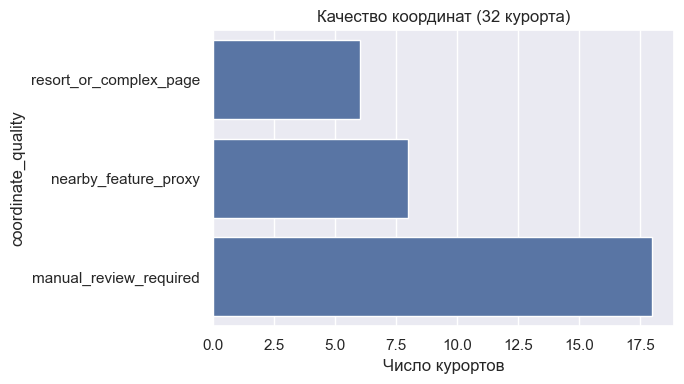

In [5]:
cq = resorts["coordinate_quality"].value_counts(dropna=False)
print(cq.to_string())
print()
print("Точные (resort_or_complex_page):", cq.get("resort_or_complex_page", 0))
print("Прокси (nearby_feature_proxy)  :", cq.get("nearby_feature_proxy", 0))
print("Требуют ручной проверки        :", cq.get("manual_review_required", 0))

fig, ax = plt.subplots(figsize=(7, 4))
order = ["resort_or_complex_page", "nearby_feature_proxy", "manual_review_required"]
sns.countplot(data=resorts, y="coordinate_quality", order=order, ax=ax)
ax.set_title("Качество координат (32 курорта)")
ax.set_xlabel("Число курортов")
plt.tight_layout()
plt.show()

### 4. Покрытие ценами (ожидание: только часть курортов)

In [6]:
n_price_resorts = prices["resort_id"].nunique()
print(f"Курортов с ценой: {n_price_resorts} из {n_ids}")
print(f"Строк (курорт x месяц x тариф): {len(prices)}")
print("Месяцы:", sorted(prices["month"].unique()))
print()
print("source_quality:")
print(prices["source_quality"].value_counts(dropna=False).to_string())

covered = set(prices["resort_id"].unique())
all_ids = set(resorts["resort_id"].unique())
missing_price = sorted(all_ids - covered)
print(f"Курортов БЕЗ цены: {len(missing_price)}")
print(missing_price)

Курортов с ценой: 9 из 32
Строк (курорт x месяц x тариф): 36
Месяцы: ['2025-12', '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06']

source_quality:
source_quality
secondary    32
official      4
Курортов БЕЗ цены: 23
['R004', 'R006', 'R008', 'R010', 'R011', 'R012', 'R014', 'R015', 'R016', 'R017', 'R018', 'R019', 'R020', 'R021', 'R023', 'R024', 'R025', 'R026', 'R027', 'R028', 'R029', 'R030', 'R031']


### 5. Пересечения OSM-радиусов (osm_overlap_warning)

In [7]:
overlap = resorts["osm_overlap_warning"].notna() & (resorts["osm_overlap_warning"] != "")
print(f"Курортов с предупреждением о пересечении: {overlap.sum()} из {len(resorts)}")
print("Радиус OSM (osm_radius_km):", resorts["osm_radius_km"].unique().tolist())
print()
print(resorts.loc[overlap, ["resort_id", "name_ru", "osm_overlap_warning"]].to_string(index=False))

Курортов с предупреждением о пересечении: 10 из 32
Радиус OSM (osm_radius_km): [6]

resort_id         name_ru                                                    osm_overlap_warning
     R001      Роза Хутор Possible overlap with Газпром Поляна (6.0 km), Красная Поляна (7.3 km)
     R002  Красная Поляна     Possible overlap with Газпром Поляна (1.6 km), Роза Хутор (7.3 km)
     R003  Газпром Поляна     Possible overlap with Красная Поляна (1.6 km), Роза Хутор (6.0 km)
     R007         Эльбрус                                   Possible overlap with Чегет (1.4 km)
     R008           Чегет                                 Possible overlap with Эльбрус (1.4 km)
     R009         Мамисон                                    Possible overlap with Цей (11.5 km)
     R010             Цей                                Possible overlap with Мамисон (11.5 km)
     R013 Большой Вудъявр    Possible overlap with КолаСпортЛэнд (1.7 km), Кукисвумчорр (6.7 km)
     R014    Кукисвумчорр Possible overlap 

### 6. Происхождение погодных данных (расхождение ERA5 / ERA5-Land)

In [8]:
print("resorts.weather_model:")
print(resorts["weather_model"].value_counts(dropna=False).to_string())
print()
print("climate_monthly.weather_model:")
print(climate["weather_model"].value_counts(dropna=False).to_string())

# Загрузчик запрашивает era5_land (src/collect_resort_open_data.py: models="era5_land"),
# а в сохранённых данных указано ERA5. Расхождение нужно сверить до климатических
# исследований (отмечено в варианте расширения Astra).
print()
print("ВНИМАНИЕ: в данных указано 'ERA5', но загрузчик запрашивает models='era5_land'.")
print("Нужно подтвердить фактическое происхождение погодных данных.")

resorts.weather_model:
weather_model
ERA5    32

climate_monthly.weather_model:
weather_model
ERA5    192

ВНИМАНИЕ: в данных указано 'ERA5', но загрузчик запрашивает models='era5_land'.
Нужно подтвердить фактическое происхождение погодных данных.


### 7. Полнота и флаги качества

In [9]:
print("completeness_pct:")
print(resorts["completeness_pct"].value_counts(dropna=False).to_string())
print()
print("quality_flags:")
print(resorts["quality_flags"].value_counts(dropna=False).to_string())

# completeness_pct = filled_required_fields / 11 (см. методику ТЗ)
# 1.0 -> 11/11, 0.909 -> 10/11
print(f"Курортов с completeness_pct = 1.0 : {(resorts['completeness_pct'] == 1).sum()}")
print(f"Курортов с completeness_pct < 1.0 : {(resorts['completeness_pct'] < 1).sum()}")

completeness_pct:
completeness_pct
0.909091    18
1.000000    14

quality_flags:
quality_flags
check coordinates                           15
coordinates are proxy; OSM radii overlap     5
None                                         4
check coordinates; OSM radii overlap         3
coordinates are proxy                        3
OSM radii overlap                            2
Курортов с completeness_pct = 1.0 : 14
Курортов с completeness_pct < 1.0 : 18


### 8. Климатические данные (climate_monthly.json)

In [10]:
print("Строк:", len(climate))
print("Уникальных resort_id:", climate["resort_id"].nunique())
print("Месяцы:", sorted(climate["month"].unique()))
print("years_count:", climate["years_count"].unique().tolist())
print()
print("Ожидание: 32 курорта x 6 месяцев (ноябрь-апрель) = 192 строки")
print(f"Факт: {len(climate)} строк, {climate['resort_id'].nunique()} курортов")
print("Дубликаты (resort_id + month):", climate.duplicated(subset=["resort_id", "month"]).sum())

Строк: 192
Уникальных resort_id: 32
Месяцы: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(11), np.int64(12)]
years_count: [5]

Ожидание: 32 курорта x 6 месяцев (ноябрь-апрель) = 192 строки
Факт: 192 строк, 32 курортов
Дубликаты (resort_id + month): 0


### 9. Росстат: покрытие регионов (trips / nights)

In [11]:
def read_rosstat(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, delimiter=";", encoding="utf-8-sig")
    df["region"] = df["Ряд"].str.rsplit(" — ", n=1).str[0].str.strip()
    df["period"] = df["Ряд"].str.rsplit(" — ", n=1).str[1].str.strip()
    return df

trips = read_rosstat(RAW / "rosstat_tourist_trips.csv")
nights = read_rosstat(RAW / "rosstat_tourist_nights.csv")

print("trips :", trips.shape, "| регионов:", trips["region"].nunique(), "| периоды:", sorted(trips["period"].unique()))
print("nights:", nights.shape, "| регионов:", nights["region"].nunique(), "| периоды:", sorted(nights["period"].unique()))

# Канонизация названий регионов (алиасы, как в эталонном скрипте)
def canonical_region(value: str) -> str:
    normalized = value.replace("–", "-").replace("—", "-").replace("ё", "е")
    normalized = " ".join(normalized.split()).strip()
    aliases = {
        "Кемеровская область - Кузбасс": "Кемеровская область",
        "Республика Северная Осетия - Алания": "Республика Северная Осетия — Алания",
        "Республика Северная Осетия-Алания": "Республика Северная Осетия — Алания",
    }
    return aliases.get(normalized, normalized)

resort_regions = {canonical_region(str(r)) for r in resorts["region"].unique()}
trips_regions = {canonical_region(r) for r in trips["region"].unique()}
nights_regions = {canonical_region(r) for r in nights["region"].unique()}

print("Регионов курортов :", len(resort_regions))
print("Покрыто в trips    :", len(resort_regions & trips_regions), "из", len(resort_regions))
print("Покрыто в nights   :", len(resort_regions & nights_regions), "из", len(resort_regions))
print("Регионы курортов БЕЗ данных trips:", sorted(resort_regions - trips_regions))

trips : (1440, 7) | регионов: 96 | периоды: ['январь', 'январь-август', 'январь-апрель', 'январь-декабрь', 'январь-декабрь*', 'январь-июль', 'январь-июнь', 'январь-май', 'январь-март', 'январь-ноябрь', 'январь-ноябрь*', 'январь-октябрь', 'январь-октябрь*', 'январь-сентябрь', 'январь-февраль']
nights: (384, 6) | регионов: 96 | периоды: ['январь-декабрь', 'январь-июнь', 'январь-март', 'январь-сентябрь']
Регионов курортов : 20
Покрыто в trips    : 20 из 20
Покрыто в nights   : 20 из 20
Регионы курортов БЕЗ данных trips: []


### Итоги аудита

**Соответствует ТЗ:**
- 32 курорта, 32 уникальных `resort_id`, 20 регионов;
- координаты без пропусков;
- климат: 192 строки = 32 курорта × 6 месяцев (ноябрь–апрель), `years_count=5`
  (сезоны 2021/22–2025/26);
- Росстат покрывает все 20 регионов.

**Проблемы / ограничения, которые нужно держать в поле зрения:**
1. **Координаты:** только 6 точных (`resort_or_complex_page`), 18 —
   `manual_review_required`, 8 — `nearby_feature_proxy`.
2. **Цены:** только 9 из 32 курортов (36 строк за 2025-12…2026-06);
   `source_quality`: 32 `secondary`, 4 `official`.
3. **OSM-пересечения:** 10 курортов с `osm_overlap_warning` (пересечение радиусов).
4. **Погода:** в данных указано `ERA5`, но загрузчик запрашивает `era5_land` —
   расхождение нужно сверить.
5. **Полнота:** 14 курортов `completeness_pct=1.0`, 18 курортов — `0.909` (10/11).

**Следующие шаги по плану:**
1. Сформировать словарь `region_key` (канонизация названий регионов) — частично
   уже заложена в проверке Росстата.
2. Зафиксировать источники и даты сбора в `README`.
3. Приоритетно заняться ценами (узкое место: 9/32).
4. Перейти к `transform` → `scoring` (витрина `resort_features` → `resort_scores`).

## Геокодинг курортов: как мы получаем координаты

Координата курорта критична: по ней строятся запросы к OpenSkiMap (трассы/подъёмники),
Overpass (инфраструктура, 25% балла), загружается погода (зимние условия, 20%) и ищется
ближайший аэропорт (доступность, 10%). Основной источник координат — OpenSkiMap (готовые
координаты `skiArea`); Wikidata и OSM-центроид — резервные.


### 1. Проблема: старые координаты и новый основной источник

Исторически координаты собирались из Wikipedia/Nominatim и часто попадали в `needs_review`
(не подтверждены). После рефакторинга основной источник — OpenSkiMap (прямой поиск `skiArea`),
а Wikipedia/Nominatim как геокодеры удалены. Теперь качество координаты — это `openskimap`
(найден напрямую), `exact` (≥2 источников согласны), `osm_centroid`/`wikidata` (резерв),
`reference` (ориентир заказчика) или `review` (не подтверждено).


In [1]:
import json
import sys
from pathlib import Path

import pandas as pd

_root = Path.cwd()
while not (_root / "data" / "raw").exists() and _root.parent != _root:
    _root = _root.parent
sys.path.insert(0, str(_root))
PROJECT_ROOT = _root

resorts = json.loads((PROJECT_ROOT / "data" / "prepared" / "resorts.json").read_text(encoding="utf-8"))
df = pd.DataFrame(resorts)

print("Качество координат (новый статус):")
print(df["coordinate_quality_new"].value_counts(dropna=False).to_string())
print()
print("Курорты без подтверждённой координаты (needs_review):")
rev = df[df["coordinate_status"] == "needs_review"][["resort_id", "name_ru"]]
print(rev.to_string(index=False))


### 2. Источники координат

Цепочка источников (по убыванию надёжности):

| Источник | Что даёт | Роль |
|---|---|---|
| **OpenSkiMap** | готовые координаты `skiArea` (поиск по названию) | основной |
| **Wikidata P625** | структурированные координаты элемента (по Q-id) | резервный |
| **OSM-центроид (Overpass)** | центроид объектов катания вокруг ориентира заказчика | резервный |
| **Ориентир заказчика** | координата из `resorts.json` | fallback |

Wikipedia и Nominatim как источники координат удалены (были «мусорными»).


### 3. Логика выбора координаты

In [2]:
from src.collect.geocode_resorts import select_coordinate  # noqa: E402

# Синтетический пример: OpenSkiMap против OSM-центроида
resort = {"resort_id": "DEMO", "latitude": 43.646, "longitude": 40.332}
candidates = [
    {"source": "openskimap", "latitude": 43.6501, "longitude": 40.3087,
     "title": "Роза Хутор"},
    {"source": "osm_centroid", "latitude": 43.6501, "longitude": 40.3087,
     "title": "центр катания (828 объектов)"},
]
decision = select_coordinate(resort, candidates)
print(json.dumps(decision, ensure_ascii=False, indent=2))


### 4. Результат геокодинга

In [3]:
verified = json.loads(
    (PROJECT_ROOT / "data" / "collected" / "coordinates_verified.json").read_text(encoding="utf-8")
)["resorts"]

rows = []
for r in verified:
    rows.append({
        "resort_id": r["resort_id"],
        "name_ru": r["name_ru"],
        "quality_new": r["quality_new"],
        "sources": "; ".join(r.get("sources_agreed", [])),
    })

res = pd.DataFrame(rows)
print("Распределение нового качества:")
print(res["quality_new"].value_counts().to_string())
print()
print("Курорты, требующие ручной проверки (review):")
print(res[res["quality_new"] == "review"][["resort_id", "name_ru"]].to_string(index=False))


### 5. Валидация: сдвиг и регион

Перед применением (`src/transform/apply_coordinates.py`) каждую новую координату
проверяем двумя независимыми способами, чтобы не допустить грубой ошибки:

1. **Сдвиг старых → новых** (гаверсинус): ≤ 8 км — норма, 8–15 км — «warn»,
   > 15 км — в очередь проверки.
2. **Регион** новой координаты через обратный геокодинг Nominatim сверяем с
   регионом курорта. Если не совпал — в очередь проверки.

In [4]:
prepared = json.loads((PROJECT_ROOT / "data" / "prepared" / "resorts.json").read_text(encoding="utf-8"))
p = pd.DataFrame(prepared)
print("Статус применения:")
print(p["coordinate_status"].value_counts().to_string())
print()
print("Примеры сдвига (топ по величине):")
show = p[["resort_id", "name_ru", "coordinate_shift_km", "coordinate_region_check", "coordinate_status"]].copy()
show = show.sort_values("coordinate_shift_km", ascending=False).head(6)
print(show.to_string(index=False))

Статус применения:
coordinate_status
updated         28
needs_review     2
warn             2

Примеры сдвига (топ по величине):
resort_id       name_ru  coordinate_shift_km coordinate_region_check coordinate_status
     R018 Морозная гора                11.80                      ok              warn
     R017       Холдоми                10.03                      ok              warn
     R025     Завьялиха                 6.08                      ok           updated
     R027      Мраткино                 5.64                      ok           updated
     R012      Телецкий                 5.63                      ok           updated
     R023    Аджигардак                 4.74                      ok           updated


### 6. Итог

- Основной источник координат — **OpenSkiMap** (прямой поиск `skiArea`).
- Курорты, не найденные в OpenSkiMap, геокодируются через Wikidata → OSM-центроид → ориентир заказчика.
- Статус `coordinate_status` сохраняется (`updated` / `needs_review`), а для дашборда
  выводится `coordinate_validation_status` (`confirmed` / `provisional` / `needs_review`).


### 7. Пересчёт зависимых показателей

Координата влияет на три блока рейтинга. После её обновления пересчитываем всё,
что от неё зависит (скрипт `src/collect/recompute_resort_data.py`):

- **OSM-инфраструктура** (Overpass, радиус 6 км) — 25% балла;
- **сложность и типы трасс** (Overpass, теги `piste:difficulty`/`piste:type`) — для категоризации райдеров (новичок/средний/продвинутый);
- **климат** (Open-Meteo Historical, ноябрь–апрель) — 20% балла;
- **ближайший аэропорт** (OurAirports) — 10% балла.

Курорты, чьи координаты не менялись (R014, R032 — `needs_review`), остаются на
прежних значениях.

Повторный запуск скрипта работает инкрементально: статичные данные (OSM-счётчики
и сложность/типы трасс), уже собранные ранее, пропускаются; флаг `--force` запускает
полный пересбор. Это позволяет дособрать только упавшие курорты (например, при
нестабильном доступе к Overpass).

In [5]:
import json

raw = json.loads((PROJECT_ROOT / "data" / "raw" / "resorts.json").read_text(encoding="utf-8"))
raw = {dict(zip(raw[0], r))["resort_id"]: dict(zip(raw[0], r)) for r in raw[1:]}
new = {r["resort_id"]: r for r in json.loads(
    (PROJECT_ROOT / "data" / "prepared" / "resorts.json").read_text(encoding="utf-8")
)}

print("Как изменились показатели у курортов со сдвигом координат:")
for rid in ("R018", "R007"):
    a, b = raw[rid], new[rid]
    shift = b.get("coordinate_shift_km")
    print(f"{rid} {b['name_ru']} (сдвиг {shift} км):")
    print(f"  снегопад/сезон  {a['avg_snowfall_cm_per_season']:.0f} -> {b['avg_snowfall_cm_per_season']:.0f} см")
    print(f"  ср. температура  {a['winter_mean_temperature_c']:.1f} -> {b['winter_mean_temperature_c']:.1f} C")
    print(f"  аэропорт         {a['nearest_airport_distance_km']} -> {b['nearest_airport_distance_km']} км")
    print(f"  трассы (OSM)     {a['piste_segments_6km']} -> {b['piste_segments_6km']}")

Как изменились показатели у курортов со сдвигом координат:
R018 Морозная гора (сдвиг 11.8 км):
  снегопад/сезон  396 -> 347 см
  ср. температура  -5.3 -> -7.6 C
  аэропорт         1.6 -> 11.9 км
  трассы (OSM)     0 -> 11
R007 Эльбрус (сдвиг 2.87 км):
  снегопад/сезон  402 -> 402 см
  ср. температура  -4.1 -> -5.4 C
  аэропорт         95.2 -> 97.4 км
  трассы (OSM)     54 -> 56


## Региональный спрос (Росстат)

агрегация федеральных данных до «регион × год» и расчёт
двух производных показателей:

- `trips_growth_2025 = trips_2025 / trips_2024 − 1`
- `avg_stay_nights_2025 = nights_2025 / trips_2025`

Это блок «региональный спрос» — 40% итогового балла (3 из 13 показателей).

Логика повторяет эталонный `prepare_model_data.py`:
поездки берём из периодов «январь-декабрь» (2023–2025) и «январь-декабрь*» (2022),
ночёвки — из «январь-декабрь» (2023–2025).

### Подготовка

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

_root = Path.cwd()
while not (_root / "data" / "raw").exists() and _root.parent != _root:
    _root = _root.parent
sys.path.insert(0, str(_root))
PROJECT_ROOT = _root

from src.transform.regional_demand import build_region_metrics, read_rosstat, split_series  # noqa: E402
from src.transform.regions import region_key  # noqa: E402

print("PROJECT_ROOT =", PROJECT_ROOT)

PROJECT_ROOT = C:\Users\urize\Travel_Designer


### 1. Сырые данные Росстата

In [2]:
RAW = PROJECT_ROOT / "data" / "raw"
trips = read_rosstat(RAW / "rosstat_tourist_trips.csv")
nights = read_rosstat(RAW / "rosstat_tourist_nights.csv")

print("Строк в trips:", len(trips))
print("Строк в nights:", len(nights))
print()
print("Пример trips:", trips[:2])
print("Пример nights:", nights[:2])

periods = sorted({split_series(str(r["series"]))[1] for r in trips})
print()
print("Периоды в trips:", periods)

Строк в trips: 1440
Строк в nights: 384

Пример trips: [{'series': 'Алтайский край — январь', '2022': 52432.0, '2023': 124555.0, '2024': 86785.0, '2025': 111837.0}, {'series': 'Алтайский край — январь-август', '2022': 1182370.0, '2023': 1574676.0, '2024': 1223525.0, '2025': 1316592.0}]
Пример nights: [{'series': 'Алтайский край — январь-декабрь', '2023': 6033880.0, '2024': 6524855.0, '2025': 7744587.0}, {'series': 'Алтайский край — январь-июнь', '2023': 2545385.0, '2024': 2868046.0, '2025': 2689398.0}]

Периоды в trips: ['январь', 'январь-август', 'январь-апрель', 'январь-декабрь', 'январь-декабрь*', 'январь-июль', 'январь-июнь', 'январь-май', 'январь-март', 'январь-ноябрь', 'январь-ноябрь*', 'январь-октябрь', 'январь-октябрь*', 'январь-сентябрь', 'январь-февраль']


### 2. Агрегация до «регион × год»

In [3]:
metrics = build_region_metrics()
df = pd.DataFrame(metrics).set_index("region_key")
cols = ["trips_2025", "trips_growth_2025", "avg_stay_nights_2025"]
show = df[cols].copy()
show["trips_2025"] = show["trips_2025"].astype(int)
show["trips_growth_2025"] = (show["trips_growth_2025"] * 100).round(1)
show["avg_stay_nights_2025"] = show["avg_stay_nights_2025"].round(2)
show.columns = ["поездки 2025", "рост 2025, %", "ночёвок/поездку 2025"]
print("Регионов:", len(show))
show

Регионов: 20


,поездки 2025,"рост 2025, %",ночёвок/поездку 2025
region_key,,,
Иркутская область,1456892,-6.9,4.25
Кабардино-Балкарская Республика,341320,-16.9,7.83
Камчатский край,516216,25.6,1.90
Карачаево-Черкесская Республика,1303991,86.3,1.75
Кемеровская область,1266539,-12.6,4.81
Краснодарский край,18427326,-3.8,6.01
Красноярский край,1887725,-2.3,3.66
Ленинградская область,8884916,-0.9,3.87
Московская область,22431311,24.6,4.30


### 3. Обязательные проверки

In [4]:
assert len(metrics) == 20, "ожидалось 20 регионов"
assert len({m["region_key"] for m in metrics}) == 20, "region_key должны быть уникальны"
missing = [m["region_key"] for m in metrics if not m["trips_2025"]]
assert not missing, f"нет trips_2025: {missing}"
assert all(m["trips_2025"] > 0 for m in metrics), "поездки должны быть положительны"
assert all(m["nights_2025"] > 0 for m in metrics), "ночёвки должны быть положительны"
print("OK: 20 регионов, все с trips_2025, значения положительны")

OK: 20 регионов, все с trips_2025, значения положительны


### 4. Сверка с эталоном

In [5]:
etalon_path = (
    PROJECT_ROOT / "ТЗ" / "Travel_Designer_Resort_Ranking"
    / "data" / "processed" / "model_data.json"
)
if etalon_path.exists():
    etalon = json.loads(etalon_path.read_text(encoding="utf-8"))["regions"]
    etalon_by = {r["region"]: r for r in etalon}
    diffs = 0
    for m in metrics:
        e = etalon_by[m["region_key"]]
        for field in ("trips_2025", "trips_growth_2025", "avg_stay_nights_2025"):
            if abs((m[field] or 0) - (e[field] or 0)) > 0.01:
                diffs += 1
                print("РАСХОЖДЕНИЕ", m["region_key"], field, m[field], e[field])
    print("Расхождений с эталоном:", diffs)
else:
    print("Эталон не найден, сверка пропущена")

Расхождений с эталоном: 0


### 5. Визуализация

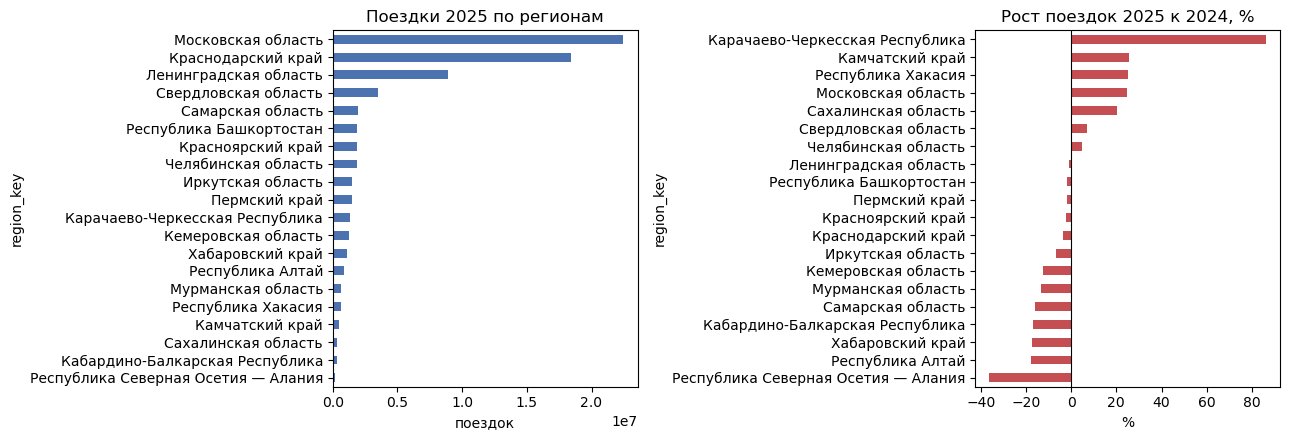

In [6]:
df = pd.DataFrame(metrics).set_index("region_key")
df["growth_pct"] = df["trips_growth_2025"] * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
df["trips_2025"].sort_values().plot(kind="barh", ax=axes[0], color="#4c72b0")
axes[0].set_title("Поездки 2025 по регионам")
axes[0].set_xlabel("поездок")

df["growth_pct"].sort_values().plot(kind="barh", ax=axes[1], color="#c44e52")
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_title("Рост поездок 2025 к 2024, %")
axes[1].set_xlabel("%")
plt.tight_layout()
plt.show()

### Итог

- 20 регионов агрегированы, все имеют `trips_2025`; значения совпадают с эталоном.
- `trips_growth_2025` и `avg_stay_nights_2025` рассчитаны и лежат в
  `data/prepared/region_metrics.json`.

**Следующий шаг:** пересчитать OSM/климат/аэропорт по новым координатам
(`data/prepared/resorts.json`), затем соединить регион × курорт в витрину
`resort_features`.

## Погода и климат курортов

Два блока, как требуется для Travel Designer:

1. **Общие климатические характеристики курорта** — статистика за сезоны
   (для выбора направления, рейтинга).
2. **Прогноз погоды на ближайшие дни** — ожидаемое состояние трассы на сленге
   райдеров с пометкой «Вероятно …» («Вероятно пухляк», «Вероятно накат»),
   плюс сами параметры погоды.

Прогноз — это оценка погодных **предпосылок** состояния трассы, а не
фактическое состояние (ратраки и нагрузка погодой не видны).

### Блок 1. Общие климатические характеристики

Из `data/prepared/resorts.json` — сезонные показатели, которые участвуют в
рейтинге (компонент «зимние условия»).

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd

_root = Path.cwd()
while not (_root / "data" / "raw").exists() and _root.parent != _root:
    _root = _root.parent
sys.path.insert(0, str(_root))
PROJECT_ROOT = _root

resorts = json.loads((PROJECT_ROOT / "data" / "prepared" / "resorts.json").read_text(encoding="utf-8"))
df = pd.DataFrame(resorts)

climate_cols = [
    "name_ru", "region", "open_meteo_elevation_m",
    "winter_mean_temperature_c", "avg_snowfall_cm_per_season",
    "avg_freezing_days_per_season", "avg_snow_days_per_season",
    "max_daily_snowfall_cm",
]
show = df[climate_cols].copy()
show.columns = ["курорт", "регион", "высота, м", "ср. температура зимы, °C",
                "снегопад за сезон, см", "морозных дней", "снежных дней",
                "макс. снегопад за сутки, см"]
show.round(1)

,курорт,регион,"высота, м","ср. температура зимы, °C","снегопад за сезон, см",морозных дней,снежных дней,"макс. снегопад за сутки, см"
0,Роза Хутор,Краснодарский край,950,3.1,390.1,46.8,92.6,47.7
1,Красная Поляна,Краснодарский край,513,7.1,390.1,16.8,92.6,47.7
2,Газпром Поляна,Краснодарский край,546,1.2,390.1,73.4,92.6,47.7
3,Шерегеш,Кемеровская область,695,-9.2,243.9,151.6,93.2,21.1
4,Архыз,Карачаево-Черкесская Республика,1655,0.5,523.2,81.6,107.6,29.5
5,Домбай,Карачаево-Черкесская Республика,1587,0.3,564.3,86.0,106.4,41.2
6,Эльбрус,Кабардино-Балкарская Республика,2146,-5.4,402.0,149.2,100.0,30.6
7,Чегет,Кабардино-Балкарская Республика,2156,-5.4,402.0,149.2,100.0,30.6
8,Мамисон,Республика Северная Осетия — Алания,2025,-6.1,315.4,156.2,99.2,20.1
9,Цей,Республика Северная Осетия — Алания,3001,-2.0,264.4,114.6,93.2,26.0


Месячный климатический профиль одного курорта (ноябрь–апрель):

In [2]:
raw = json.loads(
    (PROJECT_ROOT / "data" / "raw" / "climate_monthly.json").read_text(encoding="utf-8")
)
monthly = pd.DataFrame(raw[1:], columns=raw[0])
one = monthly[monthly["resort_id"] == "R001"]
keep = ["month", "mean_temperature_c", "avg_monthly_snowfall_cm",
        "avg_freezing_days", "avg_snow_days"]
prof = one[keep].sort_values("month").copy()
prof.columns = ["месяц", "ср. температура, °C", "снегопад, см",
                "морозных дней", "снежных дней"]
prof

,месяц,"ср. температура, °C","снегопад, см",морозных дней,снежных дней
2,1,0.806452,95.522,11.8,18.4
3,2,1.063830,100.436,10.2,18.4
4,3,4.254194,47.740,6.2,16.8
5,4,9.318000,33.768,0.2,12.4
0,11,7.113333,30.772,1.0,10.2
1,12,3.045806,81.844,5.8,16.4


### Блок 2. Прогноз погоды и состояние трассы

Сленг и погодные предпосылки:

| Состояние | Смысл | Погодный сигнал |
|---|---|---|
| **Вероятно пухляк** | свежий рыхлый снег | снегопад ≥ 10 см/сут и мороз |
| **Вероятно накат** | укатанный плотный склон | без свежего снега, мороз |
| **Вероятно каша** | мокрый тяжёлый снег | оттепель (> +2°C) или дождь |
| **Вероятно лёд** | жёсткая/обледенелая поверхность | таяние днём + заморозок ночью, тонкий покров |
| **без снега** | снега нет | покров < 0.1 м и нет снегопада |

Параметры отображаются рядом: снегопад, дождь, температура, высота покрова,
уровень нулевой изотермы, порывы ветра.

### Импорт модуля и пороги правила

In [3]:
from src.collect.fetch_weather_forecast import (  # noqa: E402
    classify_slope,
    SNOW_POWDER_CM, SNOW_LIGHT_CM, RAIN_SLUSH_MM, T_SLUSH_C,
    T_ICE_MIN_C, SNOW_DEPTH_BASE_M, SNOW_DEPTH_THIN_M, WIND_STRONG_KMH,
)

### Проверка правила на синтетике

In [4]:
cases = [
    ("обильный снегопад + мороз", 15.0, 0.0, -5.0, -9.0, 0.5),
    ("укатанный склон, мороз",     0.0, 0.0, -4.0, -8.0, 0.6),
    ("оттепель с дождём",          0.0, 3.0, 3.0, 0.0, 0.4),
    ("таяние днём, заморозок ночью", 0.0, 0.0, 1.0, -5.0, 0.2),
    ("лёгкий снег + мороз",        4.0, 0.0, -2.0, -6.0, 0.35),
    ("межсезонье, снега нет",      0.0, 0.0, 5.0, 1.0, 0.0),
]
for name, snow, rain, tmax, tmin, depth in cases:
    print(f"{name:<32} -> {classify_slope(snow, rain, tmax, tmin, depth)}")

обильный снегопад + мороз        -> Вероятно пухляк
укатанный склон, мороз           -> Вероятно накат
оттепель с дождём                -> Вероятно каша
таяние днём, заморозок ночью     -> Вероятно лёд
лёгкий снег + мороз              -> Вероятно пухляк
межсезонье, снега нет            -> без снега


### Прогноз на 7 дней по курортам (сленг + параметры)

Читаем уже сохранённый `data/collected/weather_forecast.json` — его производит
скрипт `fetch_weather_forecast.py`. Так ноутбук остаётся офлайн и
воспроизводимым: скрипт качает данные, ноутбук объясняет и показывает результат.

In [5]:
fc = json.loads(
    (PROJECT_ROOT / "data" / "collected" / "weather_forecast.json").read_text(encoding="utf-8")
)
forecasts = {r["resort_id"]: r for r in fc["resorts"] if "days" in r}

for rid in ("R001", "R004"):
    r = forecasts[rid]
    days = pd.DataFrame(r["days"])
    keep = ["date", "slope_condition", "snowfall_cm", "rain_mm",
            "temperature_min_c", "temperature_max_c", "snow_depth_m",
            "freezing_level_min_m", "wind_gusts_max_kmh"]
    print("=" * 70)
    print(r["name_ru"], "| высота точки", r["elevation_m"], "м")
    print(days[keep].to_string(index=False))
    print()

Роза Хутор | высота точки 1124.0 м
      date slope_condition  snowfall_cm  rain_mm  temperature_min_c  temperature_max_c  snow_depth_m  freezing_level_min_m  wind_gusts_max_kmh
2026-10-13       без снега          0.0      1.4                9.3               19.8           0.0                3230.0                28.4
2026-10-14       без снега          0.0      0.0               10.7               20.4           0.0                3210.0                28.8
2026-10-15       без снега          0.0      0.0               14.0               23.3           0.0                3470.0                29.5
2026-10-16       без снега          0.0      0.2               12.4               19.5           0.0                3410.0                39.6
2026-10-17       без снега          0.0      1.8               11.7               18.9           0.0                3420.0                25.9
2026-10-18       без снега          0.0      0.7               12.0               16.6           0.0       

### Ограничения

- Прогноз — оценка по **точке курорта на сетке модели** (~7–11 км), а не по
  конкретному склону.
- Это **предпосылки** состояния трассы: фактическое состояние зависит от
  обработки ратраком и нагрузки (погодой не видно).
- Пороги правила — первая гипотеза, их можно калибровать по отзывам райдеров.
- Не является прогнозом лавинной безопасности или подтверждением открытости трасс.

### Как прогноз встраивается в проект

Прогноз — это **отдельный динамический слой**, а не вход рейтинга:

| Слой | Что отвечает | Обновление | Где |
|---|---|---|---|
| Статический (рейтинг) | «какой курорт в целом зимой» | редко | `data/mart/resort_features.json` → `resort_scores.json` |
| Динамический (прогноз) | «что будет в ближайшие 7 дней» | ежедневно | `data/collected/weather_forecast.json` |

`popularity_score` считаем по климат-статистике; прогноз лишь говорит «ехать
сейчас или нет / что взять». Соединяются они **по `resort_id` на уровне
отображения**, а не хранения — чтобы не пересобирать витрину каждый день.

Страницы прототипа, которые питает прогноз:
- **«Условия катания»** — матрица «курорт × 7 дней × состояние трассы»;
- **профиль курорта** — статический профиль + живой прогноз;
- **«что взять / когда ехать»** — `slope_condition` → экипировка
  (пухляк → фрирайд-доска, лёд → канты/шлем, каша → непромокаемая одежда).

Обновление — повторный запуск `fetch_weather_forecast.py` (пишет новый снимок с
`fetched_at`). Для будущей калибровки точности снимки стоит архивировать
(`data/collected/forecast_history/...`) и подключать Ensemble API для оценки
неопределённости.

In [6]:
fc = json.loads((PROJECT_ROOT / "data" / "collected" / "weather_forecast.json").read_text(encoding="utf-8"))
print("fetched_at:", fc["fetched_at"])
print("forecast_days:", fc["forecast_days"])
print("курортов в прогнозе:", len(fc["resorts"]))

r = fc["resorts"][0]
print("\nключи одного курорта:", list(r.keys()))
print("ключ соединения с витриной:", "resort_id =", r["resort_id"])
print("дней в прогнозе:", len(r["days"]))
print("пример дня:", r["days"][0])

fetched_at: 2026-10-13T06:33:36.408317+00:00
forecast_days: 7
курортов в прогнозе: 32

ключи одного курорта: ['resort_id', 'name_ru', 'region', 'latitude', 'longitude', 'elevation_m', 'resort_elevation_m', 'days']
ключ соединения с витриной: resort_id = R001
дней в прогнозе: 7
пример дня: {'date': '2026-10-13', 'snowfall_cm': 0.0, 'rain_mm': 1.4, 'temperature_min_c': 9.3, 'temperature_max_c': 19.8, 'weather_code': 61, 'wind_gusts_max_kmh': 28.4, 'snow_depth_m': 0.0, 'freezing_level_min_m': 3230.0, 'slope_condition': 'без снега', 'strong_wind': False}


## Цены на ски-пассы: исследование и вывод

Разбираем, откуда брать цену взрослого ски-пасса (мин/макс), что у нас уже
есть, как мы пытались собрать остальное автоматически и к какому выводу пришли.

### 1. Что требует ТЗ

- Цена взрослого билета **на один день**, одна строка = курорт × месяц × тариф.
- Если указан диапазон — сохраняем обе границы (`min` и `max`).
- Агрегат: `adult_skipass_avg_rub = mean(всех непустых min и max)`.
- При отсутствии цены ценовой балл = 50, но пропуск виден в `quality_flags`.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd

_root = Path.cwd()
while not (_root / "data" / "raw").exists() and _root.parent != _root:
    _root = _root.parent
sys.path.insert(0, str(_root))
PROJECT_ROOT = _root

def load_matrix(p):
    m = json.loads(Path(p).read_text(encoding="utf-8"))
    return pd.DataFrame(m[1:], columns=m[0])

prices = load_matrix(PROJECT_ROOT / "data" / "raw" / "prices_monthly.json")
print("Структура prices_monthly.json:", prices.shape)
print("Курортов с ценой:", prices["resort_id"].nunique())
prices.head()

Структура prices_monthly.json: (36, 12)
Курортов с ценой: 9


,resort_id,resort_name,month,adult_price_min_rub,adult_price_max_rub,child_price_min_rub,child_price_max_rub,tariff_product,coverage,source_quality,source_url,checked_at
0,R001,Роза Хутор,2026-01,5550,6350,2800.0,3200.0,Ски-пасс на 1 день,05–31.01.2026; тариф менялся внутри месяца,secondary,https://skipasskp.ru/skipass-ceny-kp,46279
1,R001,Роза Хутор,2026-02,6800,6800,3400.0,3400.0,Ски-пасс на 1 день,01–28.02.2026,secondary,https://skipasskp.ru/skipass-ceny-kp,46279
2,R001,Роза Хутор,2026-03,5550,6800,2800.0,3400.0,Ски-пасс на 1 день,01–31.03.2026; изменение тарифа 10.03,secondary,https://skipasskp.ru/skipass-ceny-kp,46279
3,R001,Роза Хутор,2026-04,5190,5190,2600.0,2600.0,Ски-пасс на 1 день,01–12.04.2026,secondary,https://skipasskp.ru/skipass-ceny-kp,46279
4,R002,Красная Поляна,2025-12,3900,5250,2300.0,3050.0,Ски-пасс на 1 день,26–31.12.2025,secondary,https://skipasskp.ru/skipass-ceny-kp,46279


### 2. Что у нас было изначально

В `data/raw/prices_monthly.json` (эталон) — цены только по **9 из 32** курортов,
и это **сезон 2025/26** (на момент анализа — 13 октября 2026 — курорты ещё не
опубликовали тарифы 2026/27).

In [2]:
by = prices.groupby("resort_id").agg(
    min_price=("adult_price_min_rub", "min"),
    max_price=("adult_price_max_rub", "max"),
    source=("source_url", "first"),
)
print(by.to_string())

           min_price  max_price                                                                                                                                                                            source
resort_id                                                                                                                                                                                                        
R001            5190       6800                                                                                                                                              https://skipasskp.ru/skipass-ceny-kp
R002            3900       5250                                                                                                                                              https://skipasskp.ru/skipass-ceny-kp
R003            4100       4100                                                                                                                                 

### 3. Как мы пытались собрать остальное

Попробовали несколько путей автоматического сбора:

1. **Поисковики** (Google/Bing/DuckDuckGo/Yandex) — блокируют ботов или возвращают
   мусор (Bing выдал LinkedIn вместо курортов).
2. **Официальные сайты напрямую** — часть гео-блокирована/недоступна, часть
   рендерит цены через JavaScript (в HTML их нет).
3. **Общий краулер + парсеры на сайт** — сработало только там, где цена «1 день
   взрослый» лежит прямо в HTML.

### 4. Результат: 12 из 32 с ценой

Удалось получить цены ещё по 3 курортам (парсеры) + 9 из эталона.

In [3]:
ph = json.loads((PROJECT_ROOT / "data" / "collected" / "prices_placeholder.json").read_text(encoding="utf-8"))
df = pd.DataFrame(ph)
have = df[df["min"].notna()]
print(have[["resort_id", "name_ru", "min", "max", "status"]].to_string(index=False))
print(f"\nИтого с ценой: {len(have)} из {len(df)}")

resort_id         name_ru    min    max         status
     R001      Роза Хутор 5190.0 6800.0 эталон 2025/26
     R002  Красная Поляна 3900.0 5250.0 эталон 2025/26
     R003  Газпром Поляна 4100.0 4100.0 эталон 2025/26
     R004         Шерегеш 3100.0 3100.0         парсер
     R005           Архыз 2550.0 4350.0 эталон 2025/26
     R007         Эльбрус 3240.0 3780.0 эталон 2025/26
     R009         Мамисон 1400.0 2970.0 эталон 2025/26
     R013 Большой Вудъявр 1100.0 3420.0 эталон 2025/26
     R014    Кукисвумчорр 2000.0 2000.0         парсер
     R021      Гора Белая 2200.0 2400.0         парсер
     R022         Евразия 1450.0 3500.0 эталон 2025/26
     R032      Гладенькая 1990.0 2850.0 эталон 2025/26

Итого с ценой: 12 из 32


### 5. Ключевой вывод: нужен API агрегатора

Автоматически держать цены в актуальном состоянии **отдельными парсерами на
каждый сайт — неразумно**:

- **32 парсера = размножение сущностей** — каждый со своей логикой, regex и
  обслуживанием.
- **Сайты меняются** — вёрстка, структура, пути; придётся постоянно следить и
  чинить каждый скрипт.
- Часть сайтов **гео-блокирована**, часть **рендерит цены через JS** (нужен
  headless-браузер), часть использует тарифы «по подъёмникам» без «1 день».

**Единственный разумный путь автоматизации — доступ к API агрегатора**
(skipasskp.ru, ski.ru и т.п.): один источник, единый формат, обновляется
агрегатором. Это вопрос к заказчику — договориться об API/выгрузке цен.

До этого момента цены остаются как есть (9 курортов из эталона), а найденные
парсером значения — заглушки в `prices_placeholder.json`.

### 6. Что оставили в проекте

- `src/collect/prices/sites.py` — реестр 32 курортов → URL (для будущей привязки к API).
- `src/collect/prices/parsers/` — примеры парсеров (Шерегеш, Кукисвумчорр, Гора Белая) — как заготовка, не как основной путь.
- `src/collect/prices/run_parsers.py` — запуск парсеров + сборка `prices_placeholder.json`.
- `data/collected/prices_placeholder.json` — сводка цен с пометкой статуса.